# 05 - One-stage anchor-free detector (YOLO11)

All runs use the protocol from notebook 04: fit on folds 1-2 (every 10th frame, ignored
regions masked), tune on the fold-0 holdout, check on `val`. Every model starts from COCO
weights and is trained for 30 epochs with the same seed and default Ultralytics augmentation
(mosaic, HSV jitter, horizontal flip, random scale and translation; mosaic is switched off
for the last 10 epochs).

`af1` is the reference: every later run changes exactly one thing against it, so each effect
is measured on its own.

| Run | Change |
|---|---|
| af0_baseline_640 | YOLO11s, Ultralytics defaults, 640 px |
| af1_imgsz1152 | af0 at 1152 px, the same scale as the torchvision detectors (1920 px wide frames are scaled by 0.6) |
| af2_p2_1152 | af1 + extra stride-4 (P2) detection level |
| af3_nwd_1152 | af1 + box loss 0.5 CIoU + 0.5 NWD |
| af4_topk5_1152 / af4_topk15_1152 | af1 + task-aligned assigner top-k 5 / 15 (default 10) |

All runs use batch 8, except `af2`: it ran out of GPU memory at batch 4 in epoch 14 and was
resumed from epoch 13 with batch 2. Ultralytics accumulates gradients to the same nominal
batch of 64, so the optimisation step is unchanged.

Training is run from the terminal, for example
`python scripts/train.py configs/anchor_free/af0_baseline_640.yaml`; the script also writes
`metrics.json` and predictions that this notebook reads.

In [1]:
import json
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.analysis import classify_errors, error_summary, load_ground_truth, paired_comparison, per_clip_ap
from src.common import CLASS_NAMES, REPO_ROOT, RUNS_DIR, find_data_root
from src.predict import EVAL_SETS
from src.train_tools import load_config

FAMILY = "anchor_free"
pd.set_option("display.precision", 4)

## 1. Results on the tuning set (fold 0) and on val

In [2]:
runs = {}
for config_path in sorted((REPO_ROOT / "configs" / "anchor_free").glob("*.yaml")):
    cfg = load_config(config_path)
    run_dir = RUNS_DIR / FAMILY / cfg["name"]
    if (run_dir / "metrics.json").exists():
        runs[cfg["name"]] = {"cfg": cfg, "dir": run_dir,
                             "metrics": json.loads((run_dir / "metrics.json").read_text())}
print("finished runs:", list(runs))

main_cols = ["AP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large"]
rows = []
for name, run in runs.items():
    fold0, val = run["metrics"]["fold0"], run["metrics"]["val"]
    rows.append({"run": name, "imgsz": run["cfg"]["imgsz"],
                 **{c: fold0[c] for c in main_cols},
                 "val_AP": val["AP"], "val_AP50": val["AP50"], "ms_per_image": val["ms_per_image"]})
results = pd.DataFrame(rows).set_index("run")
results

finished runs: ['af0_baseline_640', 'af1_imgsz1152', 'af2_p2_1152', 'af3_nwd_1152', 'af4_topk15_1152', 'af4_topk5_1152']


,imgsz,AP,AP50,AP75,AP_small,AP_medium,AP_large,val_AP,val_AP50,ms_per_image
run,,,,,,,,,,
af0_baseline_640,640,0.1719,0.3234,0.1599,0.0410,0.1226,0.2912,0.1387,0.2720,43.6609
af1_imgsz1152,1152,0.2343,0.4323,0.2256,0.0671,0.1836,0.3489,0.1877,0.3746,28.7990
af2_p2_1152,1152,0.2253,0.4244,0.2094,0.0649,0.1775,0.3371,0.1686,0.3487,26.9310
af3_nwd_1152,1152,0.2389,0.4347,0.2287,0.0773,0.1843,0.3400,0.1779,0.3577,29.8080
af4_topk15_1152,1152,0.2360,0.4337,0.2270,0.0621,0.1834,0.3674,0.1923,0.3785,30.7744
af4_topk5_1152,1152,0.2378,0.4430,0.2285,0.0699,0.1819,0.3552,0.1982,0.3851,27.4198


## 2. Learning curves

mAP@[.5:.95] computed by Ultralytics after every epoch on every 20th fold-0 frame (masked
images, at most 300 detections). It is only used to compare convergence; the numbers in the
table above come from our evaluator on the original frames.

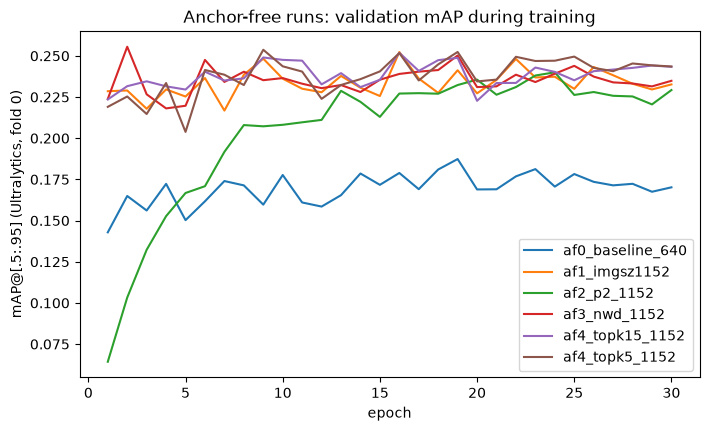

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for name, run in runs.items():
    curve = pd.read_csv(run["dir"] / "results.csv")
    curve.columns = curve.columns.str.strip()
    ax.plot(curve["epoch"], curve["metrics/mAP50-95(B)"], label=name)
ax.set_xlabel("epoch")
ax.set_ylabel("mAP@[.5:.95] (Ultralytics, fold 0)")
ax.set_title("Anchor-free runs: validation mAP during training")
ax.legend()
plt.show()

## 3. Results by object size and by class

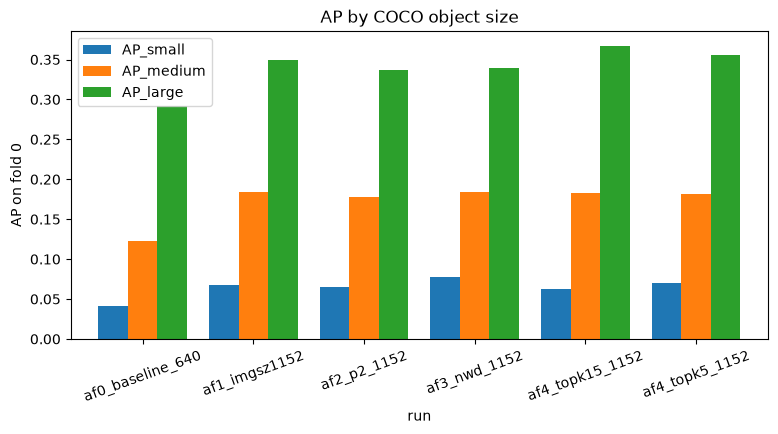

,person,bicycle,car,van,truck,tricycle,bus,motor
af0_baseline_640,0.1516,0.0177,0.4527,0.1205,0.0709,0.1439,0.3594,0.0583
af1_imgsz1152,0.2103,0.0438,0.5009,0.1882,0.1315,0.2354,0.4483,0.1161
af2_p2_1152,0.2010,0.0640,0.4992,0.1978,0.1582,0.2162,0.3579,0.1080
af3_nwd_1152,0.2120,0.0444,0.5005,0.1872,0.1542,0.2554,0.4258,0.1316
af4_topk15_1152,0.2043,0.0488,0.5005,0.1971,0.1908,0.2412,0.3812,0.1243
af4_topk5_1152,0.2189,0.0544,0.4962,0.1699,0.2075,0.1956,0.4317,0.1284


In [4]:
size_cols = ["AP_small", "AP_medium", "AP_large"]
ax = results[size_cols].plot.bar(figsize=(9, 4), width=0.8)
ax.set_ylabel("AP on fold 0")
ax.set_title("AP by COCO object size")
ax.tick_params(axis="x", rotation=20)
plt.show()

per_class = pd.DataFrame({name: {c: run["metrics"]["fold0"][f"AP_{c}"] for c in CLASS_NAMES}
                          for name, run in runs.items()}).T
per_class

## 4. Error analysis

Detections with confidence >= 0.3 on fold 0 are split into error types (`src/analysis.py`,
a simplified TIDE). Recall is the share of ground-truth boxes matched at IoU >= 0.5.

In [5]:
gt_path = EVAL_SETS["fold0"][1]
error_rows, tables = [], {}
for name, run in runs.items():
    detections = json.loads((run["dir"] / "predictions_fold0.json").read_text())
    det_table, gt_table = classify_errors(gt_path, detections, score_thr=0.3)
    tables[name] = (det_table, gt_table)
    error_rows.append({"run": name, **error_summary(det_table, gt_table)})
errors = pd.DataFrame(error_rows).set_index("run")
errors

,tp,duplicate,class,location,background,ignored,missed,recall,recall_small,recall_medium,recall_large
run,,,,,,,,,,,
af0_baseline_640,19374,1181,4228,2530,4108,3166,18267,0.5147,0.2408,0.5219,0.7999
af1_imgsz1152,23214,706,4050,2385,4667,4413,14427,0.6167,0.3786,0.6287,0.8388
af2_p2_1152,23097,727,3923,2138,5082,3364,14544,0.6136,0.3706,0.6253,0.8431
af3_nwd_1152,22860,989,3904,2338,4562,3527,14781,0.6073,0.3177,0.6248,0.8644
af4_topk15_1152,23590,876,4056,2575,5316,4357,14051,0.6267,0.3849,0.6394,0.8502
af4_topk5_1152,22927,447,3611,2130,4685,5138,14714,0.6091,0.3780,0.6200,0.8283


In [6]:
best = results["AP"].idxmax()
det_table, gt_table = tables[best]
print("best run on fold 0:", best)

recall_by_class = gt_table.groupby("class_name")["matched"].mean().reindex(CLASS_NAMES)
confusions = det_table[det_table["type"] == "class"]["class_name"].value_counts()
pd.DataFrame({"recall": recall_by_class, "class_confusion_dets": confusions}).fillna(0)

best run on fold 0: af3_nwd_1152


,recall,class_confusion_dets
class_name,,
bicycle,0.1255,219
bus,0.5526,28
car,0.8397,1017
motor,0.4190,898
person,0.5451,743
tricycle,0.5590,394
truck,0.2912,158
van,0.3547,447


## 5. Failure cases of the best run

Three frames: the one with the most missed objects, the one with the most background false
positives and the one with the most class confusions. Green: matched ground truth, red:
missed ground truth, orange: false positives, white dashed: ignored regions.

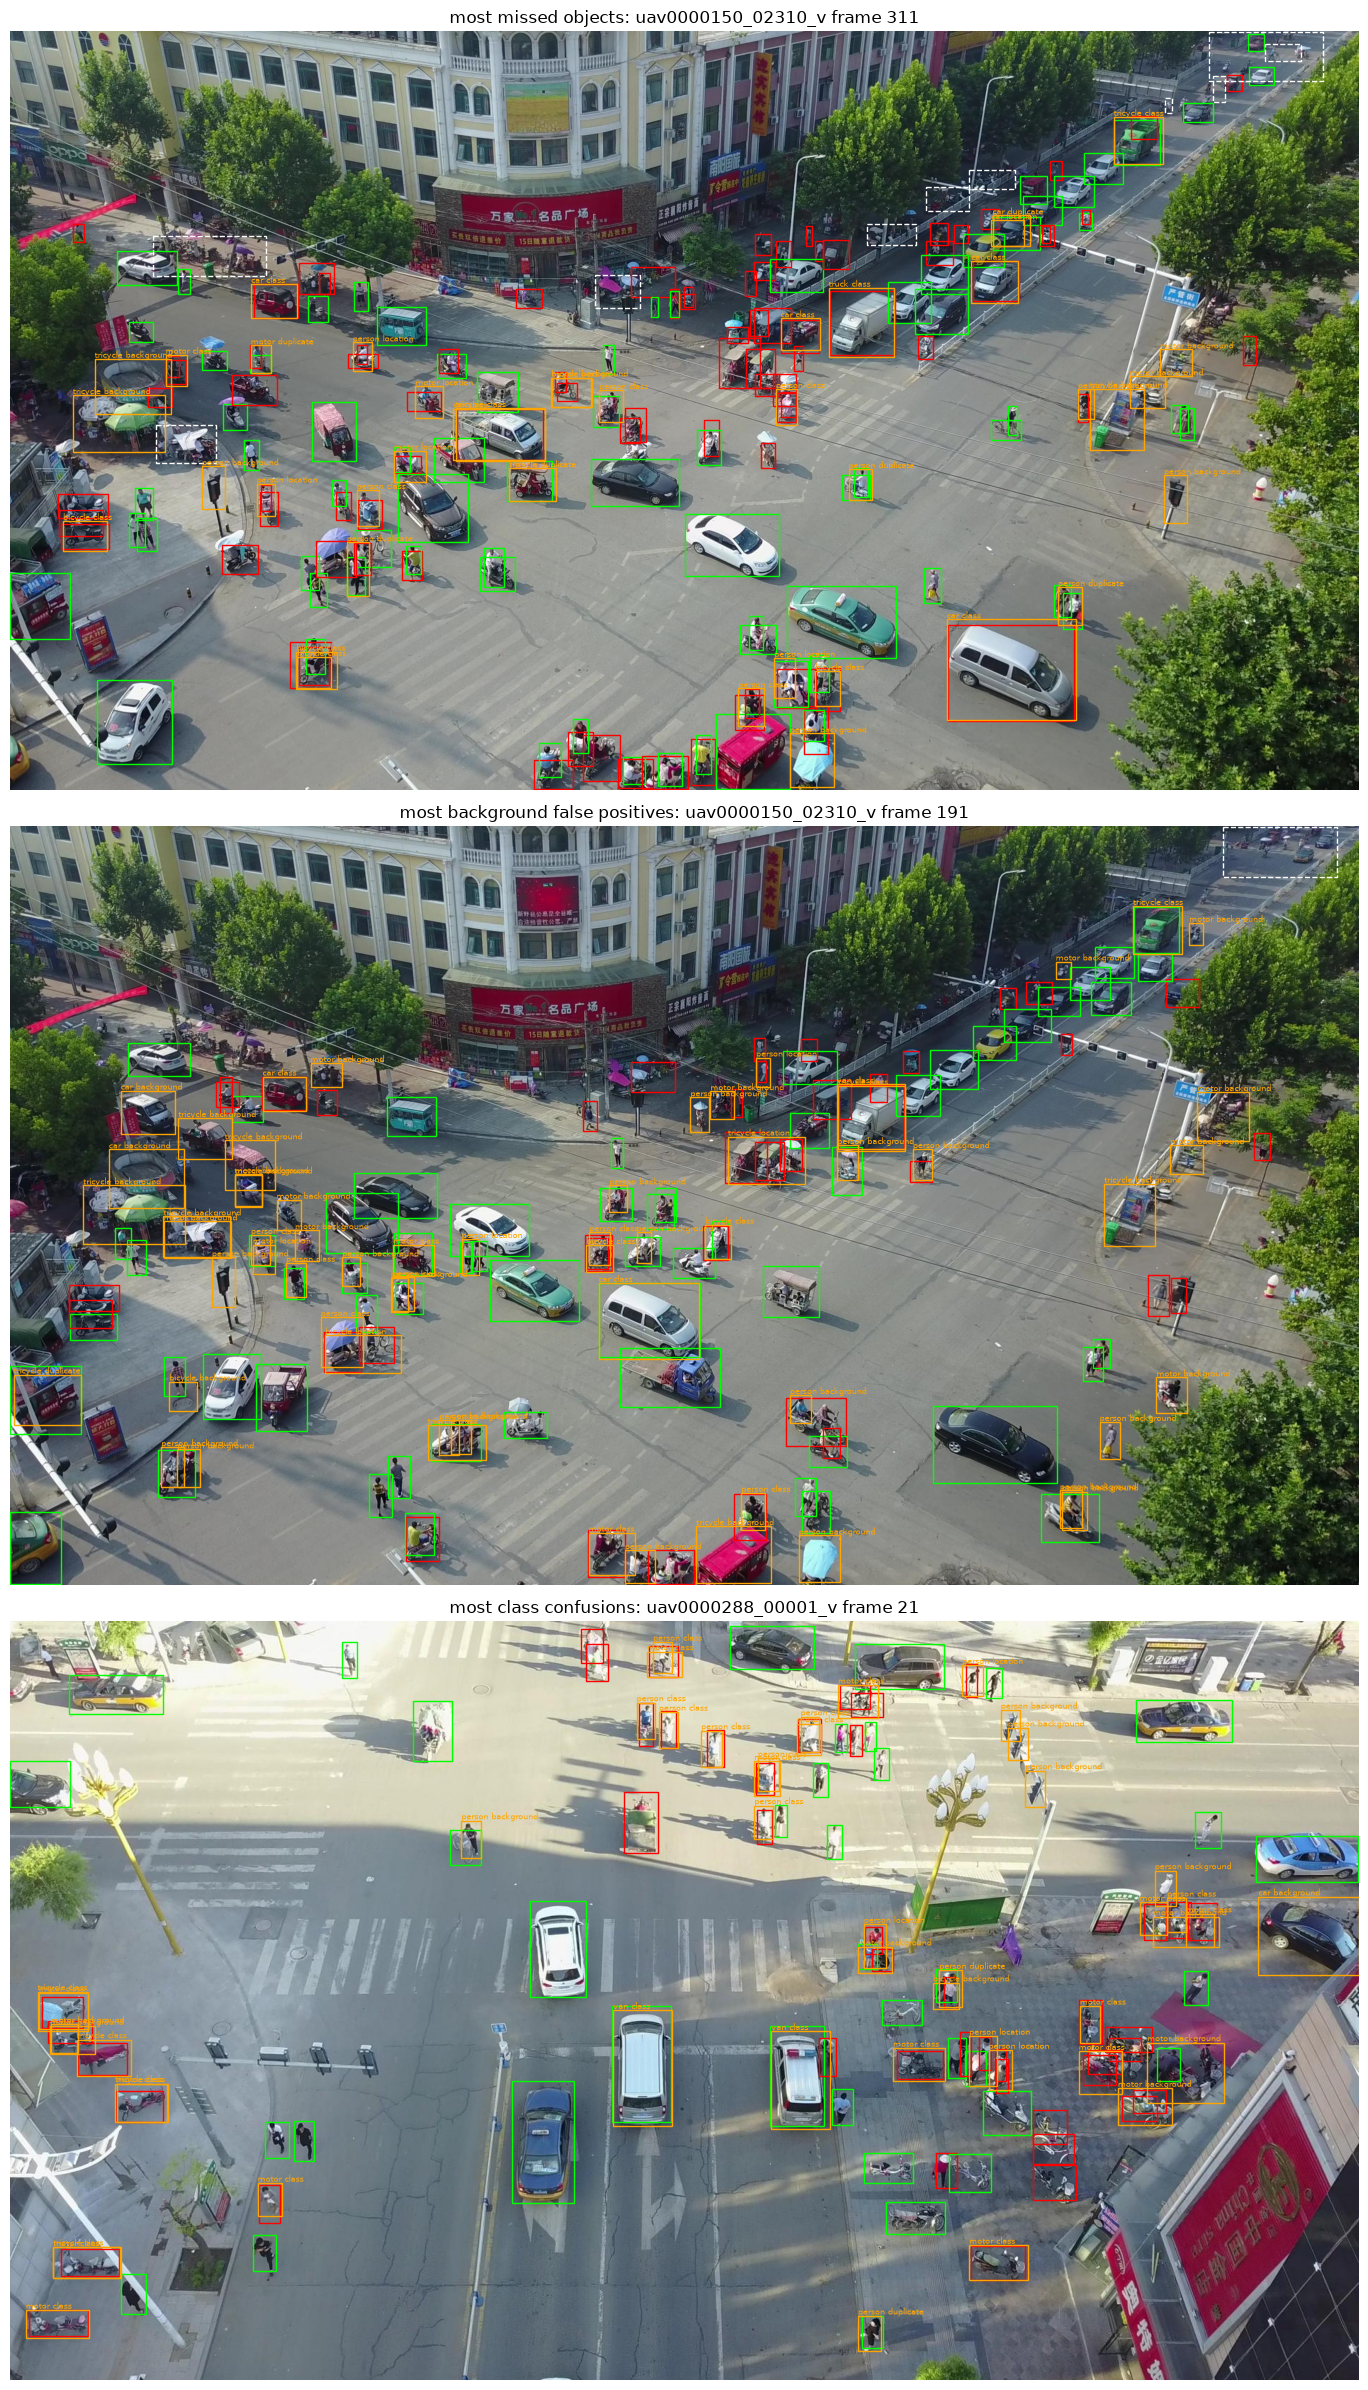

In [7]:
ground_truth = load_ground_truth(gt_path)
images = {img["id"]: img for img in json.loads(gt_path.read_text())["images"]}
best_dets = json.loads((runs[best]["dir"] / "predictions_fold0.json").read_text())


def frame_with_most(table, mask):
    return table[mask].groupby("image_id").size().idxmax()


cases = {
    "most missed objects": frame_with_most(gt_table, ~gt_table["matched"]),
    "most background false positives": frame_with_most(det_table, det_table["type"] == "background"),
    "most class confusions": frame_with_most(det_table, det_table["type"] == "class"),
}

fig, axes = plt.subplots(len(cases), 1, figsize=(14, 8 * len(cases)))
for ax, (title, image_id) in zip(axes, cases.items()):
    info = images[image_id]
    image = cv2.imread(str(find_data_root() / "train" / info["file_name"]))[:, :, ::-1]
    ax.imshow(image)

    gt, frame_gt = ground_truth[image_id], gt_table[gt_table["image_id"] == image_id]
    for (x1, y1, x2, y2), ok in zip(gt["boxes"], frame_gt["matched"]):
        ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, lw=1, ec="lime" if ok else "red"))
    for x1, y1, x2, y2 in gt["ignored"]:
        ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, lw=1, ec="white", ls="--"))

    frame_dets = sorted([d for d in best_dets if d["image_id"] == image_id and d["score"] >= 0.3],
                        key=lambda d: -d["score"])
    kinds = det_table[det_table["image_id"] == image_id]["type"].tolist()
    for det, kind in zip(frame_dets, kinds):
        if kind in ("background", "class", "duplicate", "location"):
            x, y, w, h = det["bbox"]
            ax.add_patch(plt.Rectangle((x, y), w, h, fill=False, lw=1, ec="orange"))
            ax.text(x, y - 2, f"{CLASS_NAMES[det['category_id'] - 1]} {kind}", color="orange", fontsize=6)

    ax.set_title(f"{title}: {info['video']} frame {info['frame_id']}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 6. Comparison with the anchor-based detectors

Numbers for the tuned Faster R-CNN and RetinaNet come from the two-stage and anchor-based
notebooks (same folds, frames and evaluator). Fill them in once those runs are final.

In [8]:
anchor_based = {
    # "faster_rcnn_tuned": {"AP": ..., "AP50": ..., "AP_small": ..., "AP_medium": ..., "AP_large": ..., "ms_per_image": ...},
    # "retinanet_tuned": {...},
}
compare_cols = ["AP", "AP50", "AP_small", "AP_medium", "AP_large", "ms_per_image"]
shown = [r for r in dict.fromkeys(["af0_baseline_640", best]) if r in results.index]
anchor_free = results.loc[shown, compare_cols]
pd.concat([pd.DataFrame(anchor_based).T.reindex(columns=compare_cols), anchor_free])

,AP,AP50,AP_small,AP_medium,AP_large,ms_per_image
af0_baseline_640,0.1719,0.3234,0.0410,0.1226,0.2912,43.6609
af3_nwd_1152,0.2389,0.4347,0.0773,0.1843,0.3400,29.8080


## 7. Which differences are larger than the noise?

The per-epoch curves above move by about +-0.01 mAP from one epoch to the next, which is as
large as most differences between the 1152 px runs. Every clip is an independent video, so the
AP of each of the 26 evaluation clips (19 fold-0 + 7 val) is computed separately and every run
is compared with `af1_imgsz1152` on the same clips. A difference is treated as real when
`mean_diff` is at least two standard errors away from zero.

Note on `best.pt`: Ultralytics keeps the epoch with the best curve value, and the curve is
computed on every 20th fold-0 frame. The fold-0 numbers are therefore slightly optimistic
(the same bias for all runs), while `val` is never used for any choice.

In [9]:
clip_ap = {}
for name, run in runs.items():
    clip_ap[name] = {}
    for eval_set in ("fold0", "val"):
        detections = json.loads((run["dir"] / f"predictions_{eval_set}.json").read_text())
        for clip, ap in per_clip_ap(EVAL_SETS[eval_set][1], detections).items():
            clip_ap[name][f"{eval_set}/{clip}"] = ap

comparison = paired_comparison(clip_ap, reference="af1_imgsz1152").drop(index="af1_imgsz1152")
comparison["significant"] = comparison["mean_diff"].abs() >= 2 * comparison["std_err"]
comparison

,mean_diff,std_err,clips_better,clips_worse,significant
af0_baseline_640,-0.0601,0.0079,2.0,24.0,True
af2_p2_1152,-0.0162,0.0080,7.0,19.0,True
af3_nwd_1152,0.0124,0.0091,15.0,11.0,False
af4_topk15_1152,0.0084,0.0073,17.0,9.0,False
af4_topk5_1152,0.0062,0.0069,15.0,11.0,False
